# Preprocessing, Differencing & Identifikasi Parameter Model
**Objek Data:** Penolakan Calon Pendonor Darah Akibat Kriteria Hemoglobin (HB)  
**Sumber Data:** File `data_tolak_hb.csv` (243 Hari Observasi Operasional UDD PMI Kota Surabaya)  
**Tujuan:** Melakukan pembersihan frekuensi harian, membagi data latih dan uji secara kronologis (80:20), mentransformasi data menjadi stasioner melalui *differencing*, mengidentifikasi kandidat orde SARIMA via ACF/PACF, serta menyiapkan struktur data untuk Meta Prophet.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('data_tolak_hb.csv')
df['TglPeriksa'] = pd.to_datetime(df['TglPeriksa'])
df.set_index('TglPeriksa', inplace=True)
df.sort_index(inplace=True)  # <-- TAMBAHAN: pastikan tanggal urut menaik
df = df.asfreq('D')

# Audit kelengkapan frekuensi harian setelah asfreq('D')
missing_count = df['Jumlah_Pendonor'].isna().sum()
print(f"Jumlah tanggal kosong (NaN): {missing_count} hari")

if missing_count > 0:
    missing_dates = df[df['Jumlah_Pendonor'].isna()].index.strftime('%Y-%m-%d').tolist()
    print(f"Daftar tanggal kosong: {missing_dates}")
    df['Jumlah_Pendonor'] = df['Jumlah_Pendonor'].interpolate(method='linear').round()
    print("Status: Imputasi interpolasi linear berhasil diterapkan.")
else:
    print("Status: Data lengkap tanpa tanggal yang terlewat.")

Jumlah tanggal kosong (NaN): 0 hari
Status: Data lengkap tanpa tanggal yang terlewat.


### 1. Pembagian Data Kronologis (Train-Test Split 80:20)
Data deret waktu tidak boleh diacak (*no shuffling*) agar urutan temporal tetap terjaga. Pembagian dikunci sebesar **80% data latih** dan **20% data uji** agar evaluasi antara SARIMA dan Meta Prophet berlangsung pada rentang waktu yang sama persis (*apple-to-apple*).

Data Latih (Train) : 194 hari (2026-01-01 s.d. 2026-07-13)
Data Uji (Test)    : 49 hari (2026-07-14 s.d. 2026-08-31)


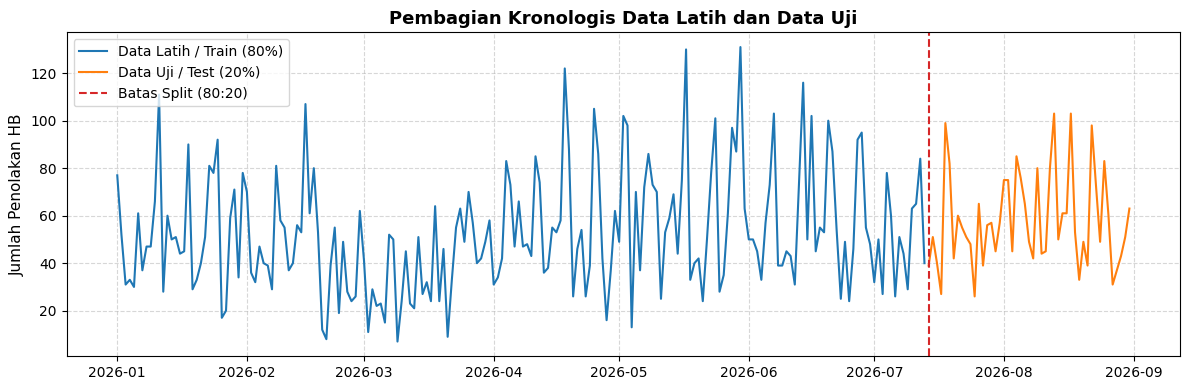

In [7]:
train_size = int(len(df) * 0.80)
train = df.iloc[:train_size].copy()
test = df.iloc[train_size:].copy()

print(f"Data Latih (Train) : {len(train)} hari ({train.index.min().date()} s.d. {train.index.max().date()})")
print(f"Data Uji (Test)    : {len(test)} hari ({test.index.min().date()} s.d. {test.index.max().date()})")

plt.figure(figsize=(12, 4))
plt.plot(train.index, train['Jumlah_Pendonor'], label='Data Latih / Train (80%)', color='#1f77b4', linewidth=1.5)
plt.plot(test.index, test['Jumlah_Pendonor'], label='Data Uji / Test (20%)', color='#ff7f0e', linewidth=1.5)
plt.axvline(test.index.min(), color='#d62728', linestyle='--', linewidth=1.5, label='Batas Split (80:20)')
plt.title('Pembagian Kronologis Data Latih dan Data Uji', fontsize=13, fontweight='bold')
plt.ylabel('Jumlah Penolakan HB', fontsize=11)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 2. Proses Differencing & Uji Ulang ADF (Khusus SARIMA)
Untuk mencegah kebocoran data (*data leakage*), proses *differencing* hanya diterapkan pada **data latih (`train`)**. Pengujian dilakukan pada dua skenario: pembedaan non-musiman ($d=1$) serta kombinasi pembedaan non-musiman dan musiman mingguan ($d=1, D=1, s=7$).

In [8]:
train_diff_1 = train['Jumlah_Pendonor'].diff(1).dropna()
train_diff_1_7 = train['Jumlah_Pendonor'].diff(1).diff(7).dropna()

print("=" * 65)
print("HASIL UJI ADF PASCA-DIFFERENCING (DATA LATIH)")
print("=" * 65)

for label, series in [
    ("First-Order Differencing (d=1)", train_diff_1),
    ("Seasonal + First Differencing (d=1, D=1, s=7)", train_diff_1_7)
]:
    res = adfuller(series)
    status = "STASIONER (Tolak H0)" if res[1] <= 0.05 else "NON-STASIONER (Gagal Tolak H0)"
    print(f"{label}")
    print(f"   ADF Statistic : {res[0]:.4f} | p-value : {res[1]:.4f} -> {status}\n")

HASIL UJI ADF PASCA-DIFFERENCING (DATA LATIH)
First-Order Differencing (d=1)
   ADF Statistic : -7.0847 | p-value : 0.0000 -> STASIONER (Tolak H0)

Seasonal + First Differencing (d=1, D=1, s=7)
   ADF Statistic : -6.1085 | p-value : 0.0000 -> STASIONER (Tolak H0)



### 3. Identifikasi Kandidat Orde SARIMA (Plot ACF & PACF)
Setelah data latih stasioner, plot **ACF** digunakan untuk membaca orde *Moving Average* ($q, Q$) dan plot **PACF** digunakan untuk membaca orde *Autoregressive* ($p, P$).

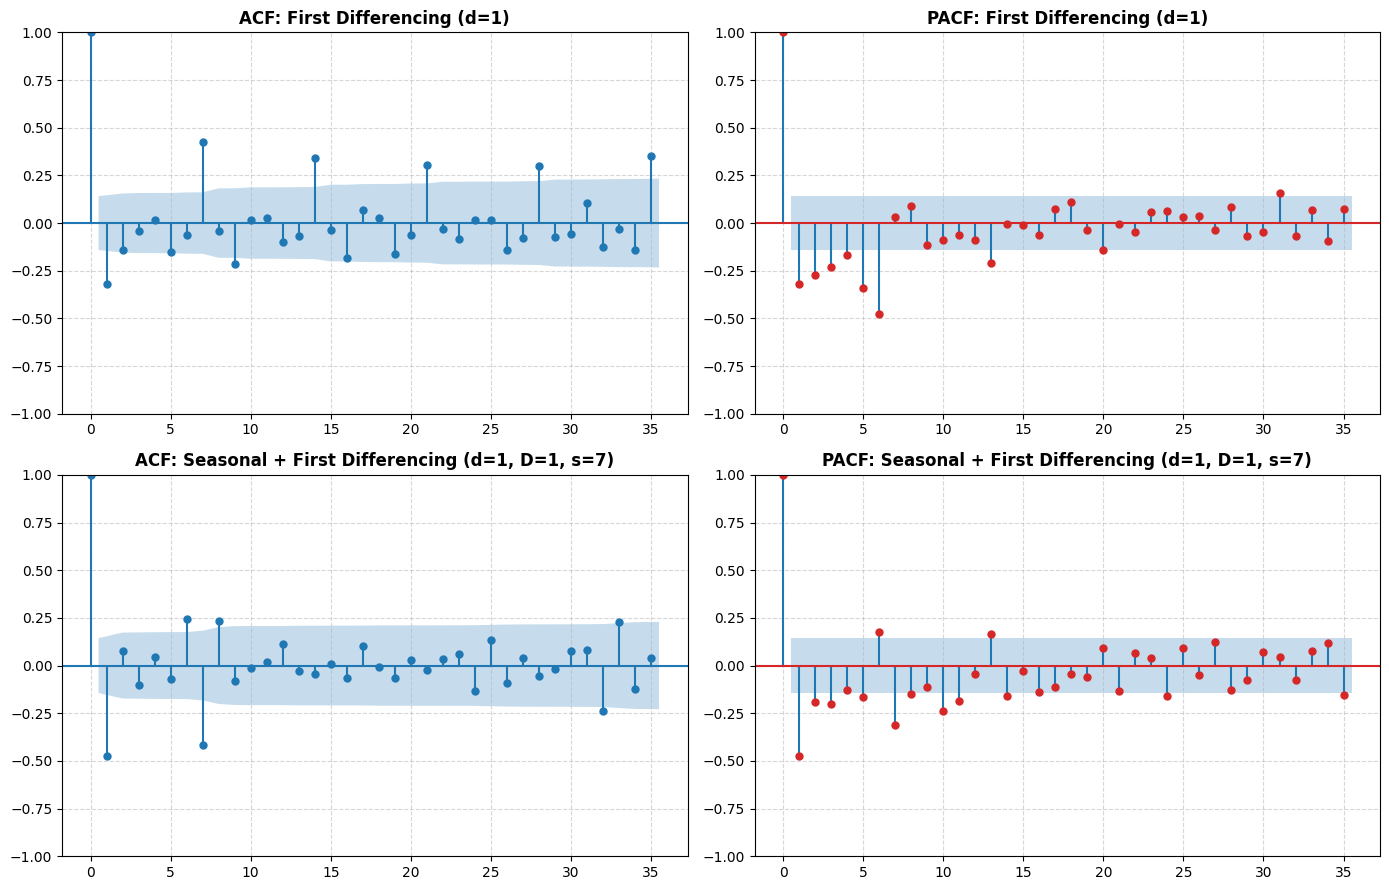

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Baris 1: First Differencing (d=1)
plot_acf(train_diff_1, ax=axes[0, 0], lags=35, color='#1f77b4')
axes[0, 0].set_title('ACF: First Differencing (d=1)', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

plot_pacf(train_diff_1, ax=axes[0, 1], lags=35, method='ywm', color='#d62728')
axes[0, 1].set_title('PACF: First Differencing (d=1)', fontsize=12, fontweight='bold')
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# Baris 2: Seasonal + First Differencing (d=1, D=1, s=7)
plot_acf(train_diff_1_7, ax=axes[1, 0], lags=35, color='#1f77b4')
axes[1, 0].set_title('ACF: Seasonal + First Differencing (d=1, D=1, s=7)', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

plot_pacf(train_diff_1_7, ax=axes[1, 1], lags=35, method='ywm', color='#d62728')
axes[1, 1].set_title('PACF: Seasonal + First Differencing (d=1, D=1, s=7)', fontsize=12, fontweight='bold')
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 4. Penyesuaian Struktur Data untuk Meta Prophet
Meta Prophet mewajibkan struktur dua kolom bernama **`ds`** (format tanggal/waktu) dan **`y`** (nilai numerik target) tanpa memerlukan proses *differencing* manual.

In [10]:
df_prophet_train = train.reset_index()[['TglPeriksa', 'Jumlah_Pendonor']].rename(
    columns={'TglPeriksa': 'ds', 'Jumlah_Pendonor': 'y'}
)
df_prophet_test = test.reset_index()[['TglPeriksa', 'Jumlah_Pendonor']].rename(
    columns={'TglPeriksa': 'ds', 'Jumlah_Pendonor': 'y'}
)

print("Preview Data Latih Meta Prophet:")
display(df_prophet_train.head())

# <-- TAMBAHAN: Simpan dataset hasil split untuk Progres 3 (Pemodelan & Evaluasi)
train.to_csv('train_sarima.csv')
test.to_csv('test_sarima.csv')
df_prophet_train.to_csv('train_prophet.csv', index=False)
df_prophet_test.to_csv('test_prophet.csv', index=False)

print("\nStatus: 4 file dataset (train/test SARIMA & Prophet) berhasil disimpan.")

Preview Data Latih Meta Prophet:


,ds,y
0,2026-01-01,77
1,2026-01-02,52
2,2026-01-03,31
3,2026-01-04,33
4,2026-01-05,30



Status: 4 file dataset (train/test SARIMA & Prophet) berhasil disimpan.


### Pembahasan Hasil Progres 2 (Untuk Laporan Progres & Poster)

1. **Kelengkapan & Pembagian Data:**
   Data deret waktu sebanyak 243 hari observasi dipastikan memiliki frekuensi harian kontinu (0 hari kosong) dan dibagi secara kronologis menjadi **194 hari data latih (80%: 1 Jan – 13 Jul 2026)** serta **49 hari data uji (20%: 14 Jul – 31 Agu 2026)** untuk menjamin evaluasi *apple-to-apple* tanpa kebocoran data (*data leakage*).

2. **Pembuktian Stasioneritas Pasca-Differencing:**
   Hasil uji *Augmented Dickey-Fuller* (ADF) pada data latih menunjukkan penurunan nilai *p-value* menjadi **$0{,}0000$ ($p < 0{,}05$)** dengan statistik ADF sebesar **$-7{,}0847$** pada *first-order differencing* ($d=1$) dan **$-6{,}1085$** pada kombinasi *seasonal + first differencing* ($d=1, D=1, s=7$). Hal ini membuktikan data telah stasioner secara rata-rata dan memenuhi syarat pemodelan SARIMA.

3. **Identifikasi Kandidat Orde SARIMA $(p,d,q)(P,D,Q)_{7}$:**
   * **Urgensi Komponen Musiman ($D=1, s=7$):** Pada plot ACF *first differencing* ($d=1$), masih terlihat lonjakan positif berulang pada kelipatan lag mingguan (**lag 7, 14, 21, 28, dan 35**) yang meluruh lambat, mengindikasikan pola musiman mingguan yang kuat.
   * **Pembacaan Orde Non-Musiman ($p, d, q$) & Musiman ($P, D, Q$):** Setelah dilakukan *seasonal differencing* ($d=1, D=1, s=7$), plot ACF terpotong tajam (*cut-off*) setelah **lag 1** ($\approx -0{,}48$) dan **lag musiman ke-7** ($\approx -0{,}42$), sedangkan plot PACF meluruh bertahap (*tails off*) pada lag awal maupun lag kelipatan 7. Pola ini mengarah pada struktur *Moving Average* dengan kandidat utama **$q=1$** dan **$Q=1$**.
   * **Daftar Kandidat Model untuk Progres 3:** Berdasarkan pembacaan tersebut, model utama yang akan diuji adalah **$\text{SARIMA}(0,1,1)(0,1,1)_{7}$** beserta model pembanding di sekitarnya: **$\text{SARIMA}(1,1,1)(0,1,1)_{7}$**, **$\text{SARIMA}(1,1,1)(1,1,1)_{7}$**, **$\text{SARIMA}(2,1,1)(0,1,1)_{7}$**, dan **$\text{SARIMA}(0,1,2)(0,1,1)_{7}$**, yang selanjutnya akan diseleksi menggunakan nilai AIC/BIC terendah.